   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 47.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 29.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


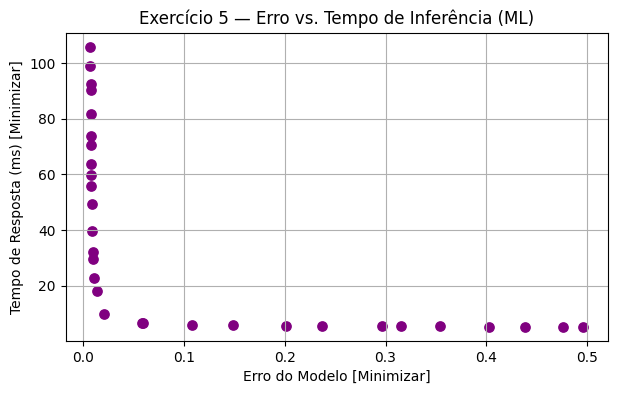

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class MLTuningProblem(ElementwiseProblem):
    def __init__(self):
        # x1: Profundidade da Árvore (1 a 30), x2: Número de Estimadores (10 a 200)
        super().__init__(n_var=2, n_obj=2, xl=np.array([1.0, 10.0]), xu=np.array([30.0, 200.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        depth, n_trees = x[0], x[1]
        f1_erro = 0.5 / (depth * np.log10(n_trees))   # Erro cai com mais árvores/profundidade
        f2_latencia_ms = (depth * 0.2) + (n_trees * 0.5) # Latência sobe
        out["F"] = [f1_erro, f2_latencia_ms]

res5 = minimize(MLTuningProblem(), NSGA2(pop_size=30), termination=('n_gen', 40), seed=7)

plt.figure(figsize=(7, 4))
plt.scatter(res5.F[:, 0], res5.F[:, 1], color='purple', s=45)
plt.title("Exercício 5 — Erro vs. Tempo de Inferência (ML)")
plt.xlabel("Erro do Modelo [Minimizar]")
plt.ylabel("Tempo de Resposta (ms) [Minimizar]")
plt.grid(True)
plt.show()